---
**Matemática para Electrónicos**

# **TRANFORMADA DE FOURIER**
# Conceptos y definiciones matemáticas

**Autor:** Prof. Dr. Ing. Sascha Spors

**Modificado:** Fernando Brunetti

**Fecha:** 16/05/23

---

# The Fourier Transform

*This Jupyter notebook is part of a [collection of notebooks](../index.ipynb) in the bachelors module Signals and Systems, Communications Engineering, Universität Rostock. Please direct questions and suggestions to [Sascha.Spors@uni-rostock.de](mailto:Sascha.Spors@uni-rostock.de).*

## Definition

The [Fourier transform](https://en.wikipedia.org/wiki/Fourier_transform), as commonly used in electrical engineering, is defined as

\begin{equation}
X(j \omega) = \int_{-\infty}^{\infty} x(t) \, e^{-j \omega t} \; dt
\end{equation}

where $X(j \omega) = \mathcal{F} \{ x(t) \}$ denotes the Fourier transform of $x(t)$. It is also termed as *spectrum* of the signal $x(t)$. The argument $j \omega$ copes for the fact that the kernel $e^{-j \omega t}$ of above [integral transform](https://en.wikipedia.org/wiki/Integral_transform) is a [harmonic exponential signal](../continuous_signals/standard_signals.ipynb#Complex-Exponential-Signal) $e^{-s t}$ with $s= j \omega$. Other common definitions of the Fourier transform may be found in the literature. They differ with respect to the sign of the exponential function and normalization factors. Sometimes the Fourier transform is evaluated in terms of the frequency $f$ instead of the angular frequency $\omega = 2 \pi f$. In both cases, the properties, theorems and transforms may differ from the ones derived in the following.

The inverse Fourier transform $x(t) = \mathcal{F}^{-1} \{ X(j \omega) \}$ is defined as

\begin{equation}
x(t) = \frac{1}{2 \pi} \int_{-\infty}^{\infty} X(j \omega) \, e^{j \omega t} \; d\omega
\end{equation}

A sufficient but not necessary condition for the existence of the Fourier transform may be derived from the absolute integrability of above Fourier integral

\begin{equation}
\int_{-\infty}^{\infty} | x(t) \, e^{-j \omega t}| \; dt \leq \int_{-\infty}^{\infty} | x(t) | \; dt < \infty
\end{equation}

where the triangle inequality and $|e^{-j \omega t}|=1$ have been used to find an upper limit of the first integral. Hence, the signal $x(t)$ has to be an [absolutely integrable function](https://en.wikipedia.org/wiki/Absolutely_integrable_function).

### Interpretation of the Spectrum

It can be concluded from the inverse Fourier transformation 

\begin{equation}
x(t) = \frac{1}{2 \pi} \int_{-\infty}^{\infty} X(j \omega) \, e^{j \omega t} \; d\omega
\end{equation}

that a signal $x(t)$ for which the Fourier transform $X(j \omega)$ exists can be represented as a superposition of weighted harmonic exponential signals $X(j \omega) \cdot e^{j \omega t}$. The angular frequency of these contributions can be related to the frequency by $f = \frac{\omega}{2 \pi}$. 

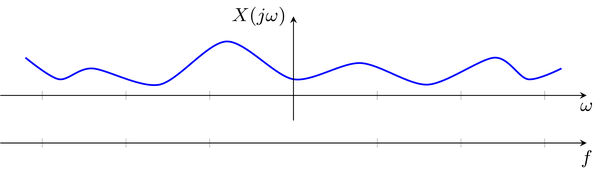

The Fourier transform is in general complex valued, $X(j \omega) \in \mathbb{C}$. It is commonly represented by its real and imaginary part $X(j \omega) = \Re \{ X(j \omega) \} + j \cdot \Im \{ X(j \omega) \}$ or by its magnitude and phase $X(j \omega) = |X(j \omega)| \cdot e^{j \varphi(j \omega)}$. The magnitude spectrum $|X(\omega)|$ provides insights into the composition of an unknown signal in terms of the level of its harmonic contributions, the phase spectrum $\varphi(j \omega)$ into their phase relations. The Fourier transformation is therefore a valuable tool in the analysis of signals.

A general spectrum $X(j \omega)$ will have non-negative contributions for negative angular frequencies $\omega < 0$. The concept of [negative frequencies](https://en.wikipedia.org/wiki/Negative_frequency) has no physical meaning. However, in the context of the Fourier transformation with its complex kernel $e^{j \omega t}$ it is for instance required to express real-valued signals.

### Transformation of the Dirac Impulse

The transform $\mathcal{F} \{ \delta(t) \}$ of the [Dirac impulse](../continuous_signals/standard_signals.ipynb#Dirac-Impulse) is derived by introducing $\delta(t)$ into the definition of the Fourier transform and exploiting the sifting property of the Dirac delta function

\begin{equation}
\mathcal{F} \{ \delta(t) \} = \int_{-\infty}^{\infty} \delta(t) \, e^{-j \omega t} dt = 1
\end{equation}

The transform of the Dirac impulse is equal to one. Hence, all angular frequencies $\omega$ are present with equal weight. This is an important property in the theory of signals and systems, since the Dirac impulse is used to characterize linear time-invariant (LTI) systems by their [impulse response](../systems_time_domain/impulse_response.ipynb) $h(t) = \mathcal{H} \{ \delta(t) \}$.

**Example**

The Fourier transform of the Dirac impulse can be derived in `SymPy` by direct evaluation of above integral

In [29]:
import sympy as sym
omega,t =sym.symbols('omega t',real = True)
class tFourier(sym.Function):
  @classmethod
  def eval(cls,arg):
    return sym.integrate(arg*sym.exp(-1j*omega*t),(t,-sym.oo,sym.oo))

class dtFourier(sym.Function):
  @classmethod
  def eval(cls,arg):
    return 1/(2*sym.pi)*sym.integrate(arg*sym.exp(1j*omega*t),(t,-sym.oo,sym.oo))




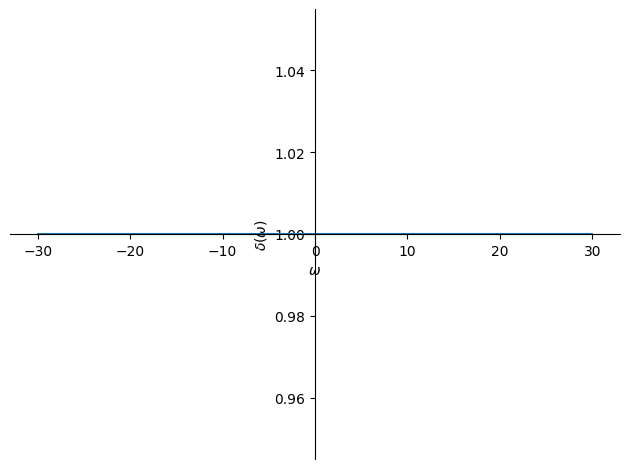

1

In [10]:


f = sym.DiracDelta(t)

F = tFourier(f)
sym.plot(F,(omega,-30,30),xlabel='$\omega$',ylabel='$\delta(\omega)$')
F


In [14]:
fprueba = dtFourier(F)
fprueba

Piecewise((0, (Abs(arg(omega) - pi/2) < pi/2) & (Abs(arg(omega) + pi/2) < pi/2)), (Integral(exp(1.0*I*omega*t), (t, -oo, oo)), True))/(2*pi)

`SymPy` provides a [Fourier transform](http://docs.sympy.org/latest/modules/integrals/integrals.html?highlight=fourier#sympy.integrals.transforms.fourier_transform). However, it is defined in terms of the frequency $f$ instead of the angular frequency $\omega$. Therefore a custom function is defined which matches the definition used here

In [35]:
class tFourier2(sym.Function):
  @classmethod
  def eval(cls,arg):
    return sym.integrals.transforms._fourier_transform(arg,t,omega,1,-1,'Fourier')

Applying this function to the Dirac impulse yields the same result as the direct evaluation of the integral above

In [25]:
X=tFourier2(sym.DiracDelta(t))
X

1

**Exercise**

* Derive the Fourier transform of a shifted Dirac impulse $\delta(t - \tau)$ either by manual evaluation of the integral or by modification of above example.

### Transformation of the Rectangular Signal

The Fourier transform $\mathcal{F} \{ \text{rect}(t) \}$ of the [rectangular signal](../continuous_signals/standard_signals.ipynb#Rectangular-Signal) is derived by explicit evaluation of the definition

\begin{equation}
\mathcal{F} \{ \text{rect}(t) \} = \int_{-\infty}^{\infty} \text{rect}(t) \, e^{-j \omega t} \; dt =
\int_{- \frac{1}{2}}^{\frac{1}{2}} e^{-j \omega t} \; dt = \frac{\sin(\frac{\omega}{2})}{\frac{\omega}{2}}
\end{equation}

The result is commonly abbreviated in terms of the [cardinal sine or sinc function](https://en.wikipedia.org/wiki/Sinc_function)

\begin{equation}
\text{sinc}(x) = \begin{cases} 
\frac{sin(x)}{x} & \text{for } x \neq 0 \\
1 & \text{for } x = 0
\end{cases}
\end{equation}

Note, that the value at $x = 0$ has been derived by applying [L'Hôpital's rule](https://en.wikipedia.org/wiki/L'H%C3%B4pital's_rule) to $\frac{sin(x)}{x}$. The sinc function is an important function in (digital) signal processing and communications engineering. It shows the following properties

1. Its maximum value is one at $x=0$

2. Its amplitude decays with $\frac{1}{|x|}$

3. Its zeros are located at $x_0 = n \cdot \pi$ for $n \in \mathcal{Z} \setminus \{0\}$

4. $\int_{-\infty}^{\infty} \text{sinc}(t) \; dt = \pi$

Using the sinc function, the Fourier transform of $\text{rect}(t)$ reads

\begin{equation}
\mathcal{F} \{ \text{rect}(t) \} = \text{sinc}\left( \frac{\omega}{2} \right)
\end{equation}

The [Laplace transform of the rectangular signal](../laplace_transform/theorems.ipynb#Transformation-of-the-rectangular-signal) is given as

\begin{equation}
\mathcal{L} \{ \text{rect}(t) \} = \frac{\sinh \left( \frac{s}{2} \right) }{\frac{s}{2}}
\end{equation}

with the $\text{ROC} \{ \text{rect}(t) \} = \mathbb{C}$. The Laplace transform of the rectangular signal can be related to its Fourier transform by using $\sinh (s) = -j \sin(j s)$ with the substitution $s = j \omega$

\begin{equation}
\frac{\sinh \left( \frac{s}{2} \right) }{\frac{s}{2}} \Bigg\vert_{s= j \omega} = \frac{\sin \left( \frac{\omega}{2} \right) }{\frac{\omega}{2}}
\end{equation}

**Example**

The Fourier transform of the rectangular signal is computed in the following. First the rectangular signal is defined

In [27]:
class rect(sym.Function):

  @classmethod
  def eval(cls,arg):
    return sym.Heaviside(arg+1/2)-sym.Heaviside(arg-1/2)

Now the Fourier transform is computed

In [28]:
X=tFourier2(rect(t))
X

2.0*sin(0.5*omega)/omega

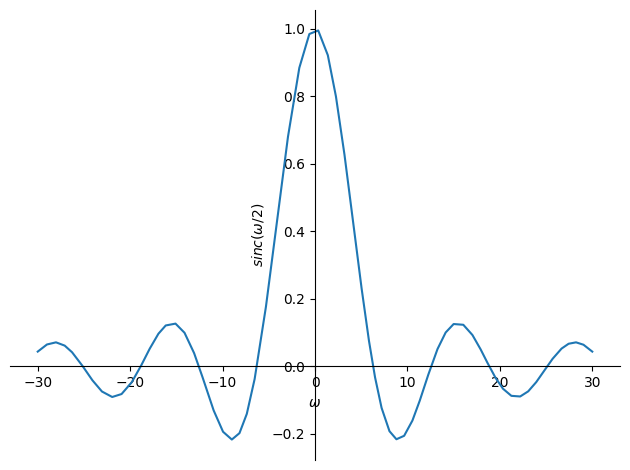

In [33]:
sym.plot(X,(omega,-30,30),xlabel='$\omega$',ylabel='$sinc({\omega}/{2})$')

**Exercise**

* Derive the Fourier transform of a scaled rectangular signal $\text{rect}(a t)$ with $a \in \mathbb{R}$ by manual evaluation of the Fourier integral or by modification of above example.
* What happens to the sinc function if you increase/decrease the width of the rectangular signal?

In [45]:
a = sym.symbols('a',real=True)

x=rect(a*t)
X1=tFourier2(x.subs(a,2))


X1


2.0*sin(0.25*omega)/omega

In [47]:
X2=tFourier2(x.subs(a,4))
X2
#Podemos ver como omega dentro del seno se divide por 2*a

2.0*sin(0.125*omega)/omega

**Copyright**

This notebook is provided as [Open Educational Resource](https://en.wikipedia.org/wiki/Open_educational_resources). Feel free to use the notebook for your own purposes. The text is licensed under [Creative Commons Attribution 4.0](https://creativecommons.org/licenses/by/4.0/), the code of the IPython examples under the [MIT license](https://opensource.org/licenses/MIT). Please attribute the work as follows: *Sascha Spors, Continuous- and Discrete-Time Signals and Systems - Theory and Computational Examples*.



---



### Relation to the Laplace Transform

The [Laplace transform](../laplace_transform/definition.ipynb) $X(s) = \mathcal{L} \{ x(t) \}$ of a signal $x(t)$ can be related to its Fourier transform $X(j \omega) = \mathcal{F} \{ x(t) \}$ by inspecting the kernels of both transforms. The Laplace transform has the complex exponential function $e^{- s t}$ with $s \in \mathbb{C}$ as kernel. The Fourier transform, as introduced above, has the harmonic exponential function $e^{- j \omega t}$ with $\omega \in \mathbb{R}$ as kernel. Both can be related to each other by considering that $s = \sigma + j \omega$. Hence, if the ROC includes the imaginary axis $s = j \omega$ of the $s$-plane, the Fourier transform of a signal $x(t)$ can be derived from its Laplace transform by

\begin{equation}
\mathcal{F} \{ x(t) \} = \mathcal{L} \{ x(t) \} \bigr\rvert_{s = j \omega}
\end{equation}

If the ROC does not include the imaginary axis, the Fourier transform cannot be derived from the Laplace transform of $x(t)$. If the ROC includes the imaginary axis $s = j \omega$ and the integration path of the inverse Laplace transform is chosen along the imaginary axis $\sigma = 0$, the inverse Laplace transform becomes identical to the inverse Fourier transform.

A benefit of the Laplace over the Fourier transform is that it exists for a wider class of signals. The one-sided Laplace transform also allows to conveniently consider initial values of differential equations.

**Example - Fourier transform of causal exponential signal**

The Fourier transform $X(j \omega) = \mathcal{F} \{ x(t) \}$ of the causal exponential signal

\begin{equation}
x(t) = \epsilon(t) \cdot e^{- \alpha t} 
\end{equation}

with $\alpha \in \mathbb{R}^+$ is derived from the Laplace transform of the [causal complex exponential signal](#Transformation-of-the-Causal-Complex-Exponential-Signal). Using the substitution $s_0 = \alpha$ yields

\begin{equation}
X(s) = \frac{1}{s + \alpha}
\end{equation}

with the ROC $\Re \{ s \} > - \alpha$. Hence for $0 < \alpha < \infty$, the ROC includes the imaginary axis. In this case the signal comprises an exponential signal whose level decays over time for $t>0$. The Fourier transform can be derived from the Laplace transform as

\begin{equation}
X(j \omega) = \frac{1}{j \omega + \alpha}
\end{equation}